# **Assignment 5. Convolutional Neural Network.**

*Authors:*

*   Camila García Vázquez **2177743**
*   Alan Zahir Lopez Rodriguez **2103115**
*   Ezequiel Sandoval Puerto **2061522**
*   Arleth Cassandra Andrade Cordova **1896113**

*Class schedule:* Thursday N3-N6


**1. Load libraries**

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.datasets import mnist

**2. Load data**

In [ ]:
(train_data, train_labels), (test_data, test_labels) = mnist.load_data()

print("MNIST dataset loaded successfully!")
print("Training images:", train_data.shape)
print("Training labels:", train_labels.shape)
print("Testing images:", test_data.shape)
print("Testing labels:", test_labels.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
MNIST dataset loaded successfully!
Training images: (60000, 28, 28)
Training labels: (60000,)
Testing images: (10000, 28, 28)
Testing labels: (10000,)


**3. Data preprocessing**

In [ ]:
# Normalize pixel values between 0 and 1
train_data = train_data.astype("float32") / 255.0
test_data = test_data.astype("float32") / 255.0

# Reshape images to include the channel dimension
train_data = train_data.reshape(-1, 28, 28, 1)
test_data = test_data.reshape(-1, 28, 28, 1)

print("Data preprocessing completed!")
print("Training data shape:", train_data.shape)
print("Testing data shape:", test_data.shape)

Data preprocessing completed!
Training data shape: (60000, 28, 28, 1)
Testing data shape: (10000, 28, 28, 1)


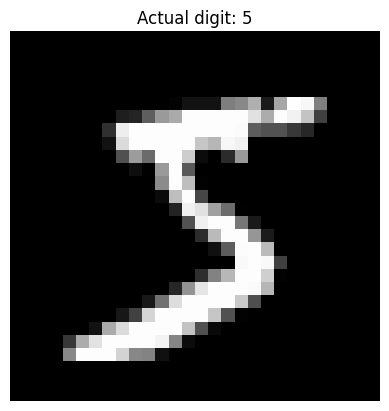

In [ ]:

# Display a sample image

plt.imshow(train_data[0].squeeze(), cmap="gray")
plt.title(f"Actual digit: {train_labels[0]}")
plt.axis("off")
plt.show()


**4. Model selection and training**

In [ ]:
# Create the CNN model
model = tf.keras.Sequential([
    tf.keras.Input(shape=(28, 28, 1)),

    # First convolutional layer
    tf.keras.layers.Conv2D(32, (3, 3), activation='relu'),
    tf.keras.layers.MaxPooling2D((2, 2)),

    # Second convolutional layer
    tf.keras.layers.Conv2D(64, (3, 3), activation='relu'),
    tf.keras.layers.MaxPooling2D((2, 2)),

    # Flatten and fully connected layers
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(64, activation='relu'),

    # Output layer
    tf.keras.layers.Dense(10, activation='softmax')
])

# Compile the model
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Display the model structure
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       102,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 121,930 (476.29 KB)

 Trainable params: 121,930 (476.29 KB)

 Non-trainable params: 0 (0.00 B)

**Explanation:**

In this part, we created the CNN using TensorFlow and Keras. We chose a Sequential model because it allows us to organize the layers one after another.

We added two convolutional layers with 32 and 64 filters to detect patterns in the handwritten digits. After each one, we used a MaxPooling layer to reduce the image dimensions while keeping the important features.

Then, we included a Flatten layer to convert the information into a single vector and a Dense layer with 64 neurons. For the output, we used 10 neurons with softmax, one for each possible digit.

To compile the model, we selected the Adam optimizer, sparse categorical crossentropy as the loss function, and accuracy to measure its performance. The model summary showed 121,930 trainable parameters.

**Model training**

In [ ]:
# Set epochs and batch size
epochs = 10
batch_size = 128

# Train the neural network using the fit() function
history = model.fit(
    train_data,
    train_labels,
    epochs=epochs,
    batch_size=batch_size,
    validation_split=0.1,
    verbose=1
)

# Display the training history dictionary
print("\nTraining History:")
for key, values in history.history.items():
    print(f"{key}: {[round(v, 4) for v in values]}")

Epoch 1/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 48s 110ms/step - accuracy: 0.9303 - loss: 0.2413 - val_accuracy: 0.9805 - val_loss: 0.0670
Epoch 2/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 78s 101ms/step - accuracy: 0.9809 - loss: 0.0636 - val_accuracy: 0.9847 - val_loss: 0.0566
Epoch 3/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 82s 100ms/step - accuracy: 0.9864 - loss: 0.0441 - val_accuracy: 0.9870 - val_loss: 0.0437
Epoch 4/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 82s 100ms/step - accuracy: 0.9892 - loss: 0.0352 - val_accuracy: 0.9880 - val_loss: 0.0426
Epoch 5/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 82s 100ms/step - accuracy: 0.9911 - loss: 0.0285 - val_accuracy: 0.9888 - val_loss: 0.0376
Epoch 6/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 42s 99ms/step - accuracy: 0.9930 - loss: 0.0221 - val_accuracy: 0.9908 - val_loss: 0.0366
Epoch 7/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 42s 100ms/step - accuracy: 0.9939 - loss: 0.0192 - val_accuracy: 0.9883 - val_loss: 0.0430
Epoch 8/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 82s 100ms/step - accuracy: 0.9952 - loss: 0.


**Explanation:**

>The neural network is trained based on the given dataset "train_data" and "train_labels" using the ".fit()" method. First, the training hyperparameters are configured with 10 epochs and a batch size of 128, defining how many complete passes the algorithm makes over the dataset and how many samples are processed before updating the model weights. 10% of the training data is reserved (validation_split=0.1) to monitor validation performance at the end of each epoch. Finally, the dictionary for the training history is displayed.




**Training accuracy and loss**

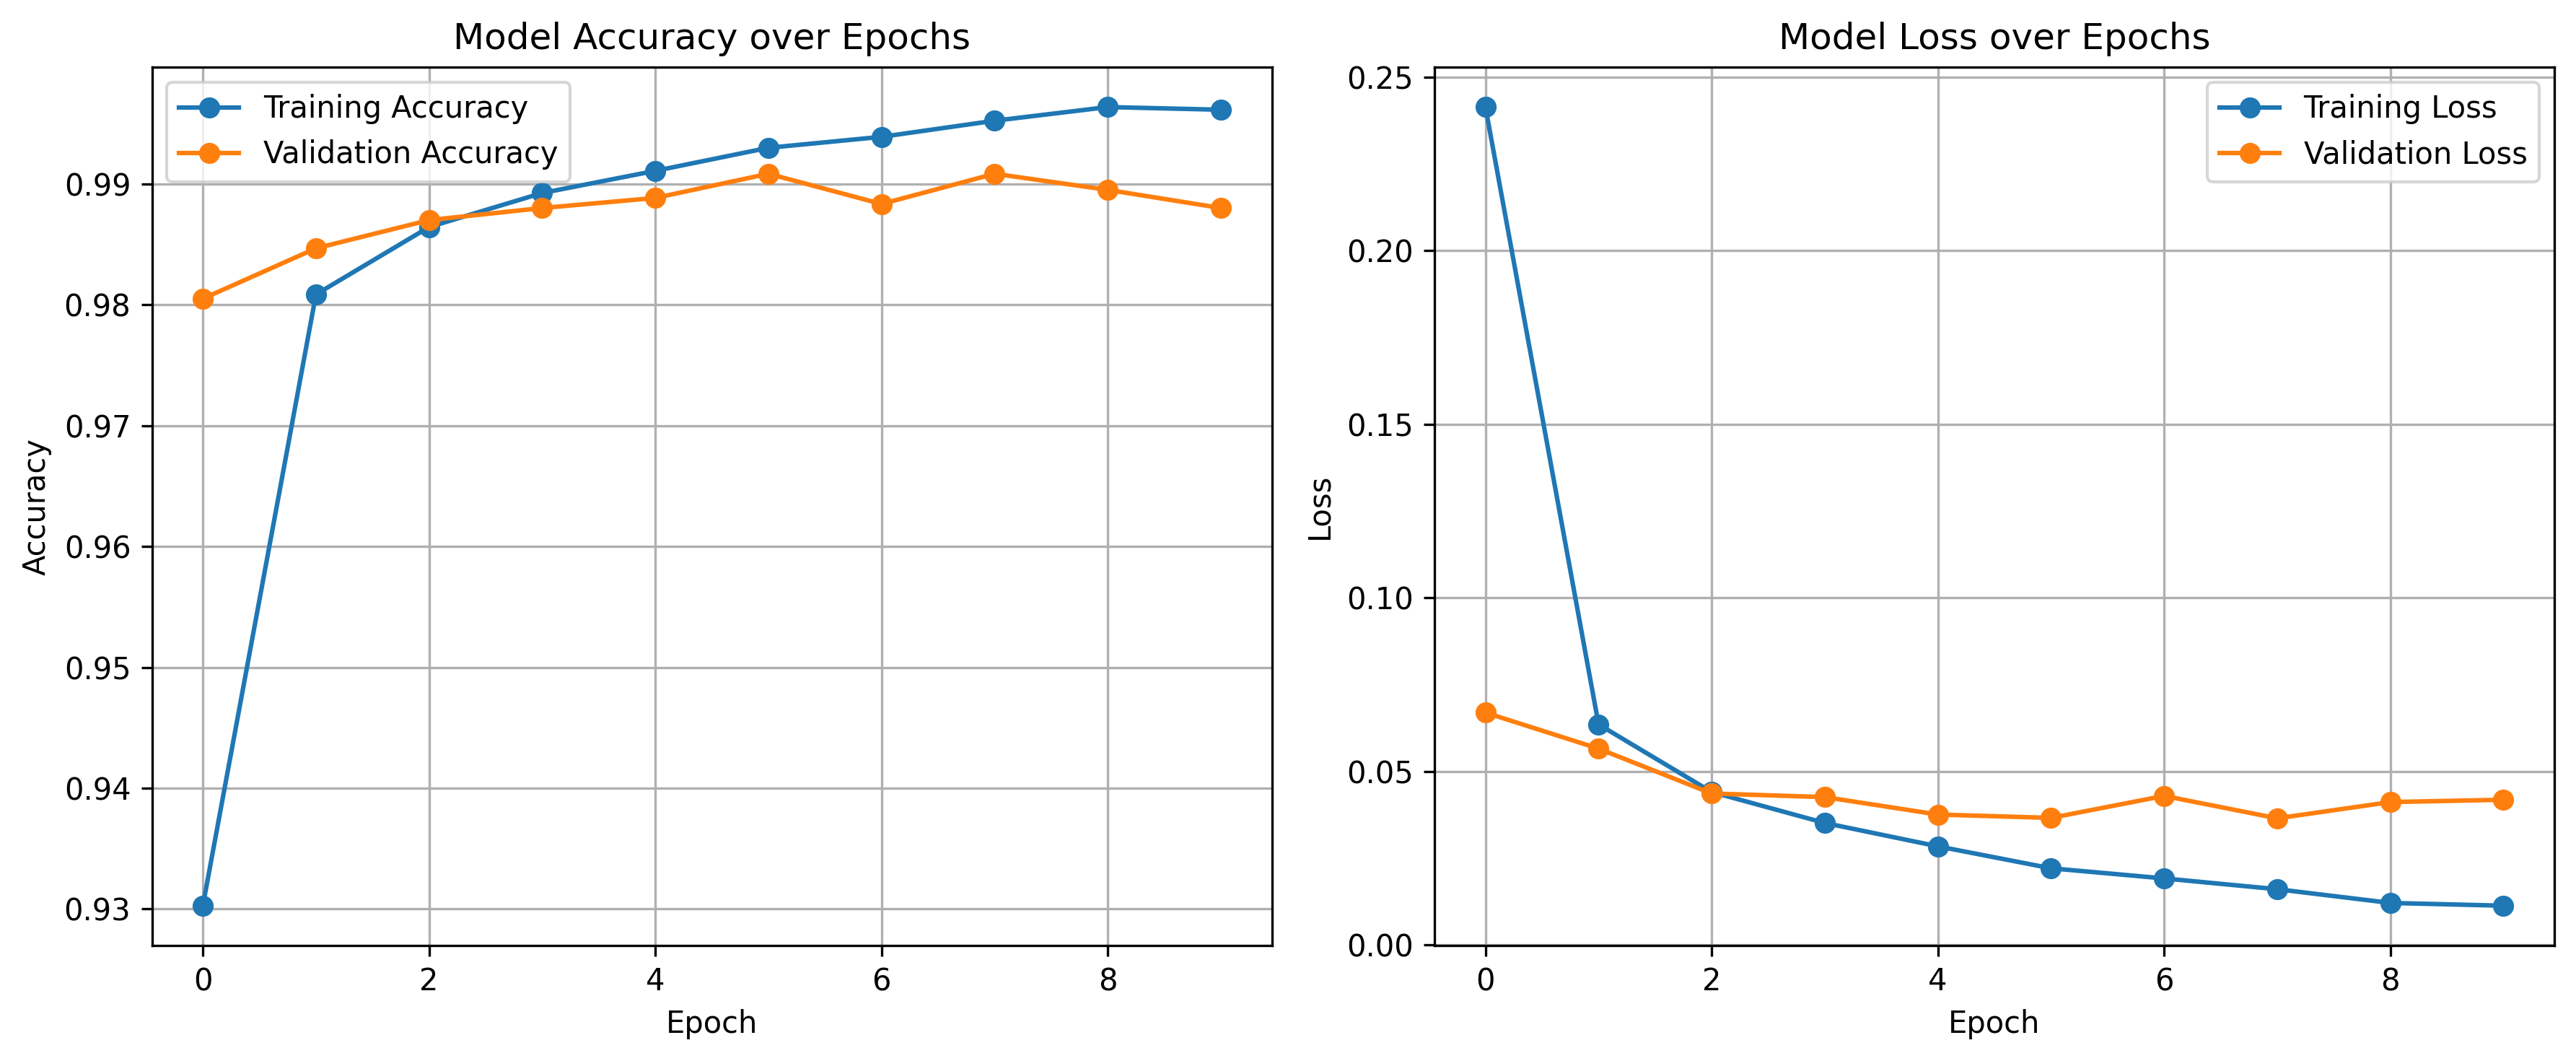

In [ ]:
# Plot training and validation accuracy and loss curves
plt.figure(figsize=(12, 5), dpi=300)

# Accuracy subplot w matplotlib
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy', marker='o')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy', marker='o')
plt.title('Model Accuracy over Epochs')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

# Loss subplot
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss', marker='o')
plt.plot(history.history['val_loss'], label='Validation Loss', marker='o')
plt.title('Model Loss over Epochs')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

**Explanation:**
> Matplotlib is used to visualize how the neural network changes throughout training. Two graphs are created using the values saved in history. The first graph compares training and validation accuracy, while the second compares training and validation loss. These graphs help us see whether the model is improving and identify possible differences between training and validation performance.

**5. Model testing**

**Evaluate the model**

In [ ]:
test_loss, test_accuracy = model.evaluate(test_data, test_labels)

# Display the model accuracy
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step - accuracy: 0.9900 - loss: 0.0352
Test Accuracy: 99.00%


**Explanation:**

>In this part, we use model.evaluate() to assess the neural network with the test images and their actual labels. We save the results in two variables: one for the model's loss and another for the accuracy of its predictions. Then we use print() to show the accuracy as a percentage, multiplying it by 100 and rounding it to two decimals to make it easier to interpret.


**Select test images and make predictions**

In [ ]:
# Select 5 images from the test dataset
sample_images = test_data[:5]

# Predict the digits in the selected images
predictions = model.predict(sample_images)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 140ms/step


**Explanation**:

>In this section, we select five images from the test set using test_data[:5]. The brackets allow us to get the first five positions of the array. Then we use model.predict() so that the neural network analyzes those images and generates the probabilities for each of the ten possible digits. We save these results in the predictions variable to use them later.


**Get the predicted digits**

In [ ]:
# Get the predicted digit for each image
predicted_digits = predictions.argmax(axis=1)

Explanation:

>In this part, we use argmax() to identify which number has the highest probability in each image. We write axis=1 because the probabilities are organized in rows, where each row corresponds to an image and the columns represent the digits from 0 to 9. Finally, we save the five predicted numbers in the variable predicted_digits.


**Get the actual digits**

In [ ]:
# Get the actual digits of the selected images
actual_digits = test_labels[:5]


**Explanation:**
>In this section, we get the actual values of the five selected images. We use test_labels because it contains the correct labels from the MNIST dataset. Then we apply [:5] to select the first five labels, which correspond exactly to the images we used in the predictions. We save these values in actual_digits so we can compare them with the results from the neural network.

**Compare predictions with actual values**

In [ ]:
# Display predicted and actual digits
for i in range(5):
    print(f"Image {i+1}: Predicted = {predicted_digits[i]}, Actual = {actual_digits[i]}")

Image 1: Predicted = 7, Actual = 7
Image 2: Predicted = 2, Actual = 2
Image 3: Predicted = 1, Actual = 1
Image 4: Predicted = 0, Actual = 0
Image 5: Predicted = 4, Actual = 4



**Explanation:**
>In this section, we use a for loop to show the five predictions along with their actual values. The range(5) function lets us repeat the instruction five times, while the variable i identifies the position of each image. We use [i] to access the corresponding values and i+1 to display the images numbered from 1 to 5. Finally, with print() we show both results so we can compare them.


**Visualize the five predictions**

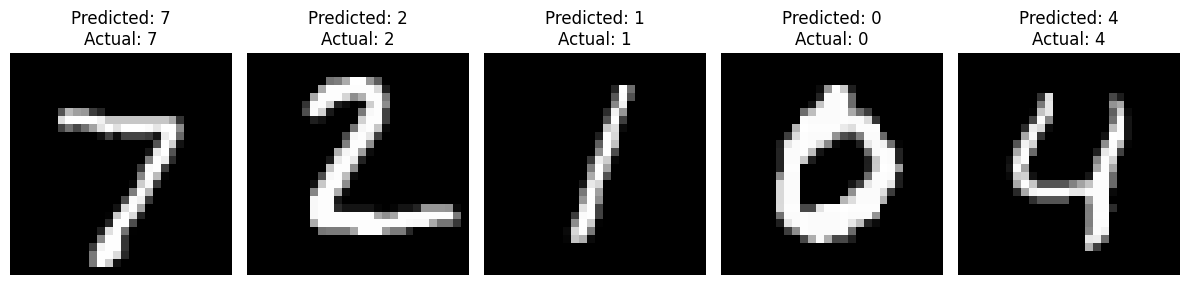

In [ ]:
# Visualize the 5 predictions
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 3))

for i in range(5):
    plt.subplot(1, 5, i+1)
    plt.imshow(sample_images[i].squeeze(), cmap="gray")
    plt.title(f"Predicted: {predicted_digits[i]}\nActual: {actual_digits[i]}")
    plt.axis("off")

plt.tight_layout()
plt.show()

**Explanation:**

>In this section, we use Matplotlib to visualize the five selected images from the test set. First, we create a horizontal figure using plt.figure() and use a for loop to place the images in five columns with subplot(). Then, with imshow(), we display each image in grayscale, using squeeze() to remove the extra channel dimension. Finally, we add a title with the predicted and actual number, hide the axes, and show the complete figure.
